In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, os, sys, time, re
from trRSA_cf import *

In [104]:
# neural data
# shape (electrodes, tps)

subject = 1
# subject = 1
frequency_band = 'unfiltered'
region = 'all'
# set to 'all' for all regions
neural_data = np.load(f'/Users/delacroix/Documents/Academia/Projects/Predictive Processing/data and code/ecog_data/npa/{region}-{frequency_band}/sub{subject}-{frequency_band}-{region}.npy')
selected_neural_data = neural_data

neural_rdm_metric = 'correlation'

selected_neural_data.shape

(99, 180000)

In [105]:
# models
# shape (n_events, features)

llama3 = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/event based embeddings/Llama_embedding_Layer3.npy')
llama10 = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/event based embeddings/Llama_embedding_Layer10.npy')
llama16 = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/event based embeddings/Llama_embedding_Layer16.npy')
llama22 = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/event based embeddings/Llama_embedding_Layer22.npy')
llama29 = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/event based embeddings/Llama_embedding_Layer29.npy')

models = [llama3, llama10, llama16, llama22, llama29]
selected_models_labels = ['llama3', 'llama10', 'llama16', 'llama22', 'llama29']
# model_rdm_metrics = ['cosine', 'cosine']
model_rdm_metrics = ['cosine', 'cosine', 'cosine', 'cosine', 'cosine']

In [ ]:
# set parameters 

n_subsamples = 100
subsampling_iterations = 100

subsample_duration_sec = 1.5

resolution = 100

tps = selected_neural_data.shape[1]
subsample_tps = int(subsample_duration_sec * resolution) # subsample size in tps - also number of RDMs calculated for each subsample

In [114]:
# selected words
# selected_word_indices = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/trRSA candidates/all_validwords.npy')
selected_word_indices = np.load('/Users/delacroix/Documents/Coding/dRSA/exploring models/candidate event selection/cond1-gpt.npy')

# select event candidates corresponding tps in the neural time series based on selected_word_indices
transcript_path = '/Users/delacroix/Documents/Academia/Projects/Predictive Processing/data and code/podcast_ECoG_data/stimuli/podcast_transcript.csv' # main transcript
df = df = pd.read_csv(transcript_path)

df_with_tps = df.copy()
df_with_tps['start'] = np.floor(df['start'] * resolution).astype(int)
df_with_tps['end'] = np.floor(df['end'] * resolution).astype(int)
df_with_tps

word_start_tps = df_with_tps['start'].to_numpy()


# Run analysis

## subsampling

In [108]:
time_series_subsample_idx, event_idx = subsampling_trRSA(tps, subsample_tps, n_subsamples, subsampling_iterations, selected_event_indices=selected_word_indices, event_start_tps=word_start_tps, mask=None, random_state=None)
print(time_series_subsample_idx.shape)
print(event_idx.shape)

(50, 100, 150)
(50, 100)


## neural RDMs

In [109]:
subsampled_neural_data = apply_subsampling_indices(selected_neural_data, time_series_subsample_idx) # shape (iterations, n_subsamples, features, subsample_tps)
neural_rdm_series = compute_rdm_series(subsampled_neural_data, neural_rdm_metric) # shape (iterations, subsample_tps, rdm_length)
print(neural_rdm_series.shape)
# so now we have neural RDM series, with target words centered based on candidate indices

(50, 150, 4950)


## models RDM

In [110]:
model_rdms_list = [compute_model_rdm(m, event_idx, metric=model_rdm_metrics[i]) for i, m in enumerate(models)]

## correlatate across time

In [111]:
rdm_correlations_mean_list = [np.mean(batched_corr(neural_rdm_series, model_rdm), axis=0) for model_rdm in model_rdms_list]
rdm_correlations_mean_list[0].shape
# also averaged iterations

(150,)

## plot

In [112]:
half = subsample_tps // 2
lags = np.arange(subsample_tps) - half     # index i -> offset i - half
lags_in_seconds = lags / resolution
n_models = len(selected_models_labels)

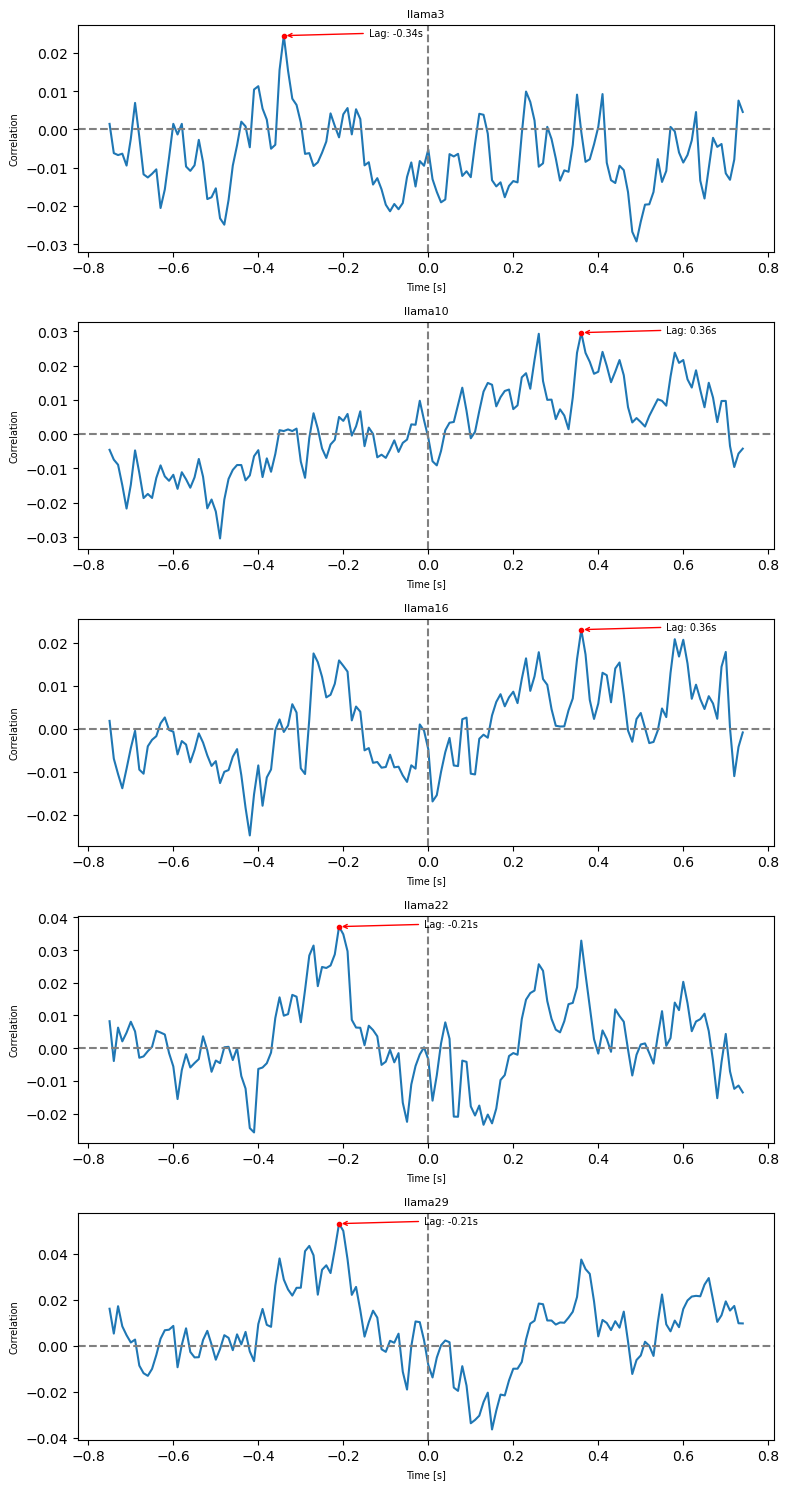

In [113]:
fig, axs = plt.subplots(n_models, 1, figsize=(8, 3 * n_models), squeeze=False)

for i in range(n_models):
    model_name = selected_models_labels[i]
    curve = np.asarray(rdm_correlations_mean_list[i])

    ax_lag = axs[i, 0]
    ax_lag.plot(lags_in_seconds, curve)

    ax_lag.axvline(0, color='gray', linestyle='--')
    ax_lag.axhline(0, color='gray', linestyle='--')
    ax_lag.set_xlabel('Time [s]', fontsize=7)
    ax_lag.set_ylabel('Correlation', fontsize=7)
    ax_lag.set_title(str(model_name), fontsize=8)

    # Peak of this model's curve
    peak_idx = int(np.argmax(curve))
    peak_lag = lags_in_seconds[peak_idx]
    peak_val = curve[peak_idx]

    ax_lag.plot(peak_lag, peak_val, 'ro', markersize=3)
    ax_lag.annotate(
        f'Lag: {peak_lag:.2f}s',
        xy=(peak_lag, peak_val),
        xytext=(peak_lag + 0.2, peak_val),
        arrowprops=dict(arrowstyle='->', color='red'),
        fontsize=7,
    )

fig.tight_layout()
plt.show()

## save

In [52]:
# save lags
save_path = Path('_results')
np.save(get_unique_path(save_path, 'output.npy'), np.asarray(rdm_correlations_mean_list))

In [51]:
# save lables
with open(save_path / 'selected_model_labels.json', 'w') as f:
    json.dump(selected_models_labels, f)

# Notes

In [ ]:
# reminder: number of subsamples will correspond to number of words